# Software Ticket Resolution Time Estimation
Lab prototype comparing Baseline, OLS Linear Regression, Polynomial Regression, Ridge, and Lasso.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures


### 1. Load and Inspect Dataset

In [2]:
df = pd.read_csv('lab_ticket_resolution.csv')
print('Dataset Shape:', df.shape)
print('\nData Types:\n', df.dtypes)
print('\nMissing Values:\n', df.isna().sum())
print('\nDescriptive Statistics:\n', df.describe())
df.head()

Dataset Shape: (240, 6)

Data Types:
 ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Missing Values:
 ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

Descriptive Statistics:
        complexity_score  lines_changed  team_experience_years    reopened  \
count        240.000000     240.000000             240.000000  240.000000   
mean           5.491667      54.820833               6.105417    0.233333   
std            2.979697      26.145017               3.391426    0.423836   
min            1.000000       1.000000               0.500000    0.000000   
25%            3.000000      33.000000               3.300000    0.000000   
50%            5.500000      54.000000               5.800000    0.00

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


### 2. Feature Selection & Target Definition
Excluding ticket_id (identifier) and lines_changed (target leakage, known only post-fix).

In [3]:
features = ['complexity_score', 'team_experience_years', 'reopened']
target = 'resolution_hours'

X = df[features]
y = df[target]

### 3. Train/Test Split (80/20)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f'Training samples: {len(X_train)}, Testing samples: {len(X_test)}')

Training samples: 192, Testing samples: 48


### 4. Dummy Regressor (Baseline)

In [5]:
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

metrics = {}
metrics['Dummy (Mean)'] = {
    'MAE': mean_absolute_error(y_test, y_pred_dummy),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_dummy)),
    'R2': r2_score(y_test, y_pred_dummy)
}

### 5. Linear Regression

In [6]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

metrics['Linear Regression'] = {
    'MAE': mean_absolute_error(y_test, y_pred_lr),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    'R2': r2_score(y_test, y_pred_lr)
}

### 6. Polynomial Regression (Degree 2 & 3 with CV)

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for deg in [2, 3]:
    poly_pipe = make_pipeline(PolynomialFeatures(degree=deg), StandardScaler(), LinearRegression())
    cv_scores = cross_val_score(poly_pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    poly_pipe.fit(X_train, y_train)
    y_pred_poly = poly_pipe.predict(X_test)
    print(f'Degree {deg} CV RMSE: {-cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')
    metrics[f'Polynomial (deg={deg})'] = {
        'MAE': mean_absolute_error(y_test, y_pred_poly),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_poly)),
        'R2': r2_score(y_test, y_pred_poly)
    }

Degree 2 CV RMSE: 3.5118 (+/- 0.2904)
Degree 3 CV RMSE: 3.6221 (+/- 0.2318)


### 7. Ridge & Lasso with Cross-Validation

In [8]:
alphas = np.logspace(-3, 3, 50)

# Ridge
ridge_pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=kf))
ridge_pipe.fit(X_train, y_train)
best_ridge_alpha = ridge_pipe.named_steps['ridgecv'].alpha_
y_pred_ridge = ridge_pipe.predict(X_test)
metrics[f'Ridge (alpha={best_ridge_alpha:.4f})'] = {
    'MAE': mean_absolute_error(y_test, y_pred_ridge),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
    'R2': r2_score(y_test, y_pred_ridge)
}

# Lasso
lasso_pipe = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=kf, random_state=42))
lasso_pipe.fit(X_train, y_train)
best_lasso_alpha = lasso_pipe.named_steps['lassocv'].alpha_
y_pred_lasso = lasso_pipe.predict(X_test)
metrics[f'Lasso (alpha={best_lasso_alpha:.4f})'] = {
    'MAE': mean_absolute_error(y_test, y_pred_lasso),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
    'R2': r2_score(y_test, y_pred_lasso)
}

pd.DataFrame(metrics).T

,MAE,RMSE,R2
Dummy (Mean),9.113952,10.597685,-0.021017
Linear Regression,2.590540,3.219153,0.905791
Polynomial (deg=2),2.781772,3.552811,0.885249
Polynomial (deg=3),2.823330,3.624918,0.880544
Ridge (alpha=0.1207),2.591127,3.219486,0.905771
Lasso (alpha=0.0010),2.590628,3.219185,0.905789


### 8. Diagnostics: Observed vs Predicted & Residuals

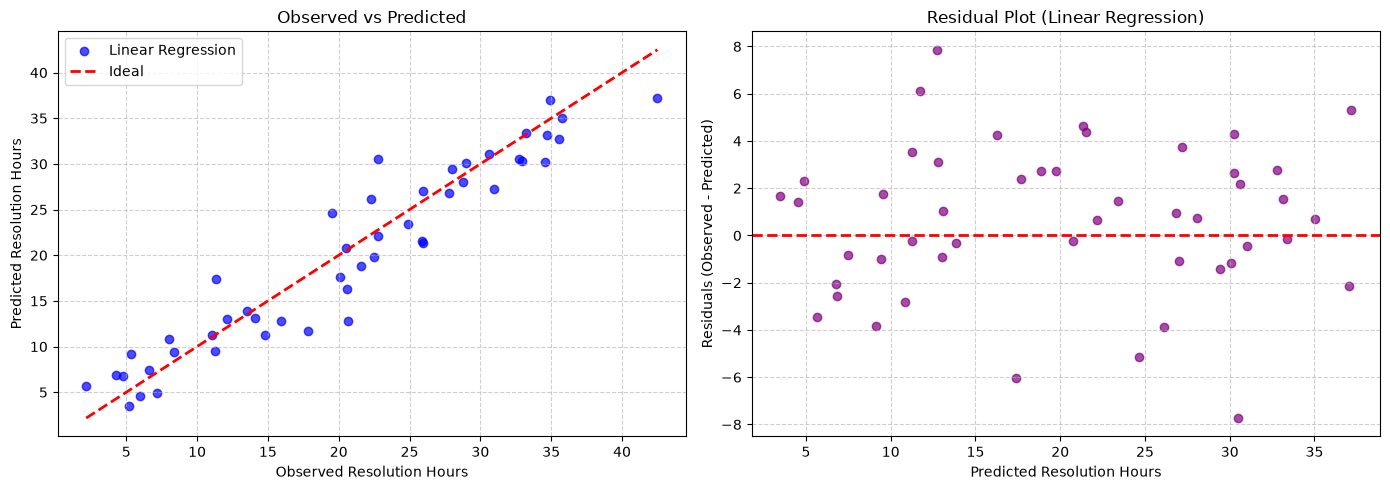

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Observed vs Predicted
axes[0].scatter(y_test, y_pred_lr, alpha=0.7, color='blue', label='Linear Regression')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal')
axes[0].set_xlabel('Observed Resolution Hours')
axes[0].set_ylabel('Predicted Resolution Hours')
axes[0].set_title('Observed vs Predicted')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Residuals
residuals_lr = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals_lr, alpha=0.7, color='purple')
axes[1].axhline(0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Resolution Hours')
axes[1].set_ylabel('Residuals (Observed - Predicted)')
axes[1].set_title('Residual Plot (Linear Regression)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()